# PoC


Setup + dane (10 ras)


In [3]:
import random
from pathlib import Path
from PIL import Image

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split

NUM_CLASSES = 10
BATCH = 32
EPOCHS = 5
LR = 0.001
SEED = 2718

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("device:", device)

images_dir = Path("data/Images")

wszystkie_foldery = []
for p in images_dir.iterdir():
    if p.is_dir():
        wszystkie_foldery.append(p)

rasy = random.sample(wszystkie_foldery, NUM_CLASSES)
rasy = sorted(rasy)

class_to_id = {}
id_to_class = {}
for i, rasa in enumerate(rasy):
    class_to_id[rasa.name] = i
    id_to_class[i] = rasa.name
    print(i, rasa.name)

samples = []
for rasa in rasy:
    numer_klasy = class_to_id[rasa.name]
    for plik in rasa.iterdir():
        rozszerzenie = plik.suffix.lower()
        if rozszerzenie == ".jpg" or rozszerzenie == ".jpeg":
            samples.append((plik, numer_klasy))

print("ile zdjec:", len(samples))

etykiety = []
for sciezka, lab in samples:
    etykiety.append(lab)

train_s, tmp = train_test_split(
    samples,
    test_size=0.2,
    stratify=etykiety,
    random_state=SEED,
)

etykiety_tmp = []
for sciezka, lab in tmp:
    etykiety_tmp.append(lab)

val_s, test_s = train_test_split(
    tmp,
    test_size=0.5,
    stratify=etykiety_tmp,
    random_state=SEED,
)

print("train:", len(train_s))
print("val:  ", len(val_s))
print("test: ", len(test_s))


device: cpu
0 n02085620-Chihuahua
1 n02085782-Japanese_spaniel
2 n02089078-black-and-tan_coonhound
3 n02092002-Scottish_deerhound
4 n02092339-Weimaraner
5 n02094114-Norfolk_terrier
6 n02096051-Airedale
7 n02096294-Australian_terrier
8 n02106662-German_shepherd
9 n02116738-African_hunting_dog
ile zdjec: 1779
train: 1423
val:   178
test:  178


Dataset + loader


In [4]:
tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class DogsDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path)
        img = img.convert("RGB")
        img = tfm(img)
        return img, label

train_ds = DogsDataset(train_s)
val_ds = DogsDataset(val_s)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False)

images, labels = next(iter(train_loader))
print("images:", images.shape)
print("labels:", labels[:8])


images: torch.Size([32, 3, 224, 224])
labels: tensor([7, 5, 8, 6, 8, 5, 1, 2])


Model


In [5]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=LR)

print(model.fc)


Linear(in_features=512, out_features=10, bias=True)


Trening


In [6]:
for epoch in range(EPOCHS):
    model.train()
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        opt.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        opt.step()

        preds = logits.argmax(dim=1)
        correct = correct + (preds == labels).sum().item()
        total = total + labels.size(0)

    train_acc = correct / total

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            preds = model(images).argmax(dim=1)
            correct = correct + (preds == labels).sum().item()
            total = total + labels.size(0)

    val_acc = correct / total
    print("epoch", epoch + 1, "train_acc", train_acc, "val_acc", val_acc)


epoch 1 train_acc 0.7182009838369642 val_acc 0.398876404494382
epoch 2 train_acc 0.8706957132817991 val_acc 0.5674157303370787
epoch 3 train_acc 0.9072382290934645 val_acc 0.7528089887640449
epoch 4 train_acc 0.9198875614898102 val_acc 0.6235955056179775
epoch 5 train_acc 0.9451862262825017 val_acc 0.7696629213483146


Predykcja


true: Japanese_spaniel
pred: Japanese_spaniel


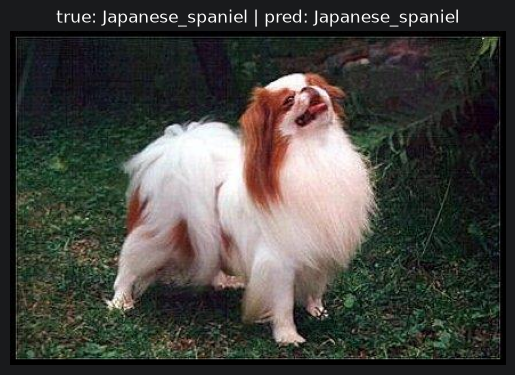

In [7]:
path, true_y = val_s[0]
img = Image.open(path)
img = img.convert("RGB")

x = tfm(img)
x = x.unsqueeze(0)
x = x.to(device)

model.eval()
with torch.no_grad():
    pred = model(x).argmax(dim=1).item()

true_name = id_to_class[true_y].split("-")[-1]
pred_name = id_to_class[pred].split("-")[-1]

print("true:", true_name)
print("pred:", pred_name)

plt.imshow(img)
plt.title("true: " + true_name + " | pred: " + pred_name)
plt.axis("off")
plt.show()
